In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns;sns.set()
from scipy.stats import mode
from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import silhouette_score
from sklearn.datasets import make_blobs

# Unsupervised learning
- clustering is a process of grouping similer data points together based on their characters.

till now we worked with datasets that had both independent variables(the features) and a dependent variable(the target).We built models that predict the value of the dependent variable from the independent variables.
- in unsupervised learning we dont have that luxury.We only have independant variables and must find patterns in them on our own.

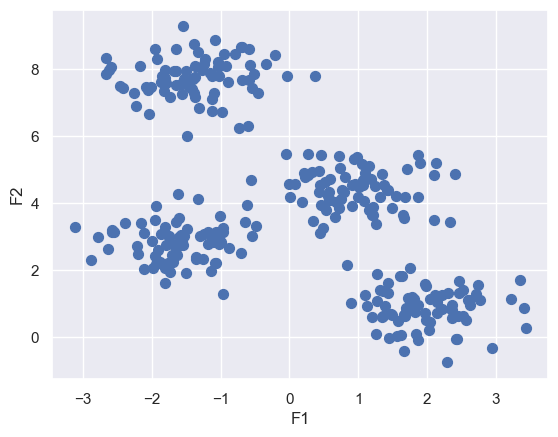

In [ ]:
# a toy dataset of 300 points spread over 4 groups
# make_blobs also returns true group pf every point
X,y_true = make_blobs(n_samples=300,centers=4,cluster_std=0.60,random_state=0)
plt.scatter(X[:,0],X[:,1],s=50)
plt.xlabel('F1')
plt.ylabel('F2')
plt.show()

We can clearly see a pattern:
- There are 4 dinstint grps of points.The goal of cluster analysis is to find such natural groupings automatically and to determine which group a new observation belongs to.
- in clustering the groups are discoverd from the data.

# practical applications of a k-means clustering
- customer segmentation
- image compression
- document clustering
- anomaly detection

image data shape (1797, 64)


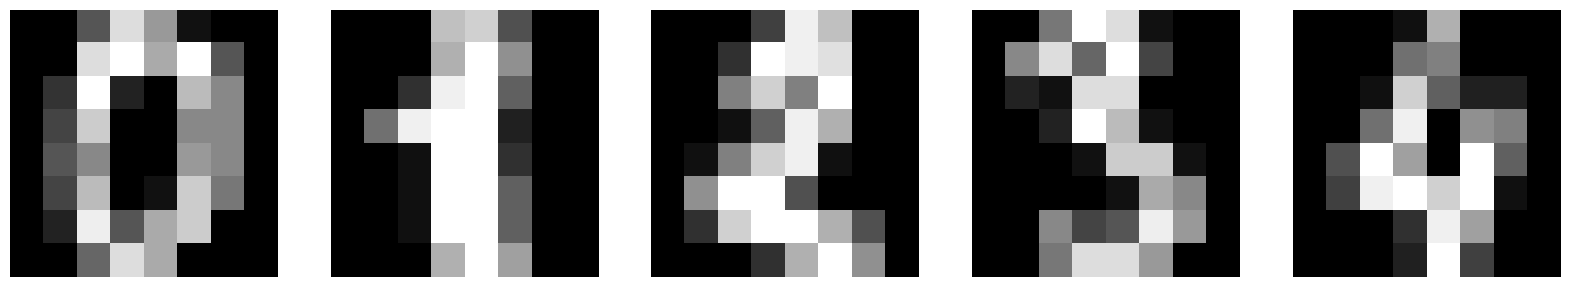

In [7]:
digits = load_digits()
print("image data shape", digits.data.shape)

plt.figure(figsize=(20,4))
for index,image in enumerate(digits.data[0:5]):
    plt.subplot(1,5,index+1)
    plt.imshow(np.reshape(image,(8,8)),cmap=plt.cm.gray)
    plt.axis('off')
plt.show()

# Model
The k-means algorithm has one important hyperparameter,k: The number of clusters we want to find.The algorithms works as follows:
- choose k points in the feature space as initial cluster centers
- assign each observation to the nearest cluster center
- recalculate each cluster center as the mean of all observations assigned to it
- repeat steps 2 and 3 untill the cluster assignments no longer change

More formally: The algorithms follows an expectation-Maximization approach:
- initialize the cluster centers
- repeat untill convergence:
        - E-step: assign each point to the nearest cluster center
        - M-step: move each cluster center to the mean of the points assigned to it

# kMeans steps
- choose k...K represent the number of cluster we want..example k=3
- the algorithms initialize 3 points randomly...this points are called centroids...a centroids represents the center of a cluster...
- assign data points ...the algorithm the distance between every data using euclidean distance(root{(x2-x1)^2+(y2-y1)^2})
- update centroids..the calculate updates the avg positiion of all points in each cluster ...the avg becomes the new centroids then.
- the it repeats the whole steps again (calculate distance,assign points to the nearest centroids,recalculate again untill the centroid stop changing significantly)...this is called covergence

# Centroid
- a centroid is a mathmatical center of a cluster.
imagine three data points X = 2,4,6 Y=4,6,8

the centroid is calculated taking the avg of each dimension-
- centroid-X = (2+4+6/3) = 4
- centroid-Y = (4+6+8/3) = 6
so the centroid is (4,6)...it represent the center of those three points

# The objective function
- Kmeans tries to make the points inside each cluster as close as possible to their centroids

$$
J = \sum_{i=1}^{K} \sum_{x \in C_i}
\|x - \mu_i\|^2
$$

* J = Total error (WCSS).
* K = Number of clusters.
* C_i = Data points belonging to cluster i.
* x = Individual data point.
* \mu_i = Centroid of the cluster.
* \|x-\mu_i\|^2 = Squared distance between the data point and centroid.

In [ ]:
# fit kMeans with k=4 and get the cluster of everypoint
kmeans_blobs = KMeans(n_clusters=4,n_init=10,random_state=0)
blob_cluster = kmeans_blobs.fit_predict(X)

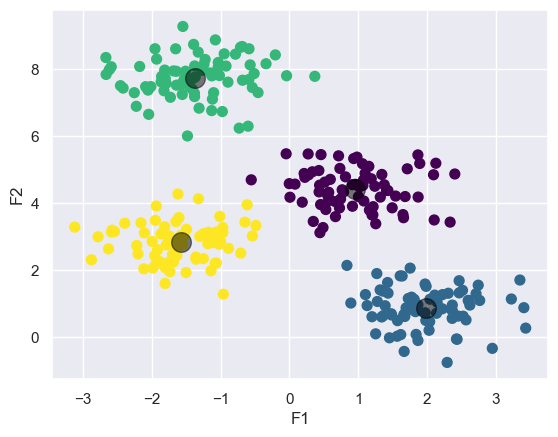

In [9]:
# color each point by its cluster and mark the cluster centers with a black dot
plt.scatter(X[:,0],X[:,1],c=blob_cluster,s=50,cmap='viridis')
centers = kmeans_blobs.cluster_centers_
plt.scatter(centers[:,0],centers[:,1],c='black',s=200,alpha=0.5)
plt.xlabel('F1')
plt.ylabel('F2')
plt.show()

Without seeing a single label,k-means has found the 4 groups we spotted by eye.Eaach center(block dot) lies in the middle of its group

# Model estimation
Apply k-means to the digits...ask for 10 cluster since we espect one cluster per digit
- n_init=10: run the algorithm 10 times...wach time with different starting centers and keep the result with the lowest inertia
- random_state=0 makes the random starting centers reproducible so  we get the same results everytime we run the notebook

In [10]:
kmeans = KMeans(n_clusters=10,n_init=10,random_state=0)
clusters = kmeans.fit_predict(digits.data)
kmeans.cluster_centers_.shape

(10, 64)

the result is 10 cluster with 64 values each

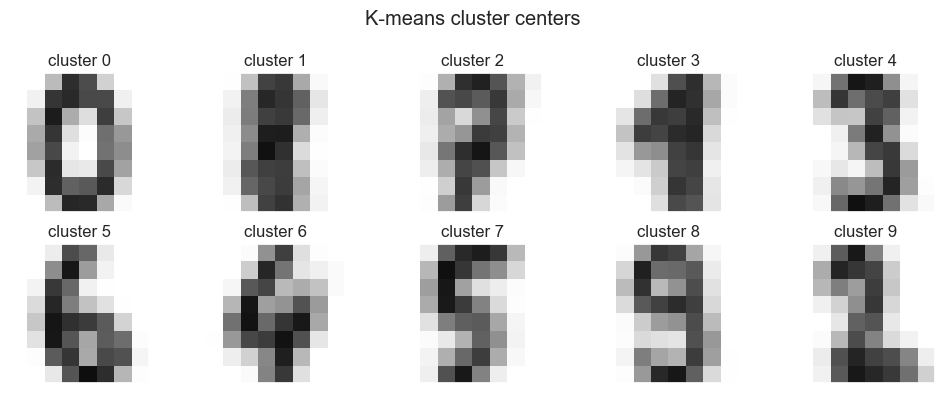

In [11]:
fig,ax = plt.subplots(2,5,figsize=(10,4))
centers = kmeans.cluster_centers_.reshape(10,8,8)
for i ,(axi,center) in enumerate(zip(ax.flat,centers)):
    axi.imshow(center,interpolation='nearest',cmap=plt.cm.binary,vmin=0,vmax=16)
    axi.set_title('cluster %i'%i)
    axi.set_xticks([])
    axi.set_yticks([])
fig.suptitle('K-means cluster centers')
plt.tight_layout()
plt.show()

even without using any labels,k-means has found clusters whose centers look like real digits:
- clearly visible = the centers of cluster 0,2,4,5,6,7,9 are easy to read as 0,7,3,6,4,5,2. This digits have a distinctive shape that differs from all other digits
- ambiguous: clusters 1 and 3 both look like a 1 but cluster 1 is much blurrer than cluster 3...cluster 8 also looks like 9 but it is also blurry
- missing: none of the centers looks like an 8

# model evaluation
In unsupervised learning...clustering, evaluation is harder...in real applications we dont have the true labels...so there is nothing to compare with....for the digits, however, we do have the labels.

- kmeans numbers and its clusters in an arbitary order.Cluster 0 is not necessarily the digit 0...first we need to translate each cluster into a digit

- for each cluster, we look up the most common true digits among its images
- that digits becomes the "predicted" label for every image in the cluster
- example: if cluster 2 mostly contains 7s, every image in cluster 2 is predicted to be a 7

In [12]:
labels = np.zeros_like(clusters)
for i in range(10):
    mask=(clusters==i)
    labels[mask]=mode(digits.target[mask])[0]
    print('Cluster %i: most common digit %i | digit counts:'%(i,mode(digits.target[mask])[0]),np.bincount(digits.target[mask],minlength=10))

Cluster 0: most common digit 0 | digit counts: [176   0   1   0   0   0   1   0   0   0]
Cluster 1: most common digit 1 | digit counts: [  0 100   8   7   2   0   3   2 100   1]
Cluster 2: most common digit 7 | digit counts: [  0   0   3   7  11   0   0 174   5   8]
Cluster 3: most common digit 1 | digit counts: [ 0 54  2  0  3  0  0  2  6 20]
Cluster 4: most common digit 3 | digit counts: [  0   1  13 154   0   2   0   0   2   6]
Cluster 5: most common digit 6 | digit counts: [  0   2   0   0   0   1 177   0   2   0]
Cluster 6: most common digit 4 | digit counts: [  2   0   0   0 165   2   0   0   0   0]
Cluster 7: most common digit 5 | digit counts: [  0   1   0   2   0 136   0   1   4   6]
Cluster 8: most common digit 9 | digit counts: [  0   0   2  13   0  41   0   0  52 139]
Cluster 9: most common digit 2 | digit counts: [  0  24 148   0   0   0   0   0   3   0]


this confirms what we saw in the cluster centers: clusters 1 and 3 both as labeled as 1,so no cluster is labeled as 8...
- when there is a tie..mode() returns the smallest value

In [13]:
# accuracy score
accuracy_score(digits.target,labels)

0.7918753478018921

the model labels about 79% of all digits correctly...
The model makes two types of errors:
- Variation within a digit: The same digit can be written in very different ways(as we saw the two cluster for 1)
- similarity between digits: diff digits can look alike,especially at a resolution of only 8*8 pixels


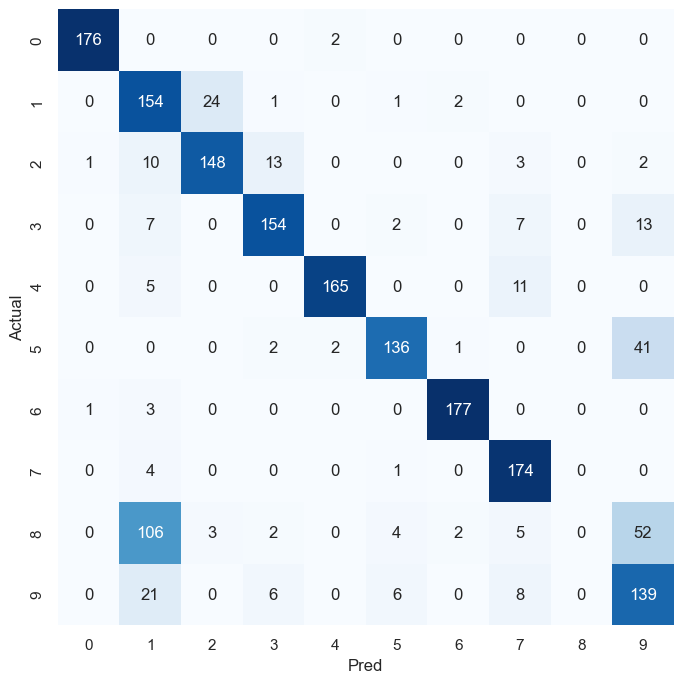

In [15]:
# check the model mistake...confusion matrix
cm = confusion_matrix(digits.target,labels)
plt.figure(figsize=(8,8))
sns.heatmap(cm,square=True,annot=True,fmt='d',cbar=False,cmap='Blues',xticklabels=digits.target_names, yticklabels=digits.target_names)
plt.xlabel('Pred')
plt.ylabel('Actual')
plt.show()

the most common misclassifications are:
- 8 predicted as 1 for 106 times..and as 9 52 times(not a single 8 is labeled correctly in the model)
- 9 predicted as 1 21 times
- 1 predicted as 2 24 times
- 5 predicted as 9 41 times and etc
all of these confusions have the same cause: k-means groups images whose pixels are close to each other.It has no idea what a digit is supposed to look like.when two digits share many dark pixels,their images end up close together in the 64 dimensional feature space and can end up is the same cluster


# choosing optimal K
The kMeans algorithm requires to specifiy the number of cluster as a hyperparameter.for the digit we knew to choose the k=10(0-9)...but for real world application like movie genres etc...its not possible
- there is no predetermined number of clusters, yet we still need to choose a value for k
- we compared our clusters to the true labels,,,but in real applications this usually isnt possible.instead we can measure how compact the clusters are using the inertia
- the inertia always decrease wehn we add more clusters....instead we fit the model for different values of k and look for the point where adding an extra cluster stops making a big difference.on a plot this this point looks like a bend in an arm,which is why this tech is called the ELBOW METHOD

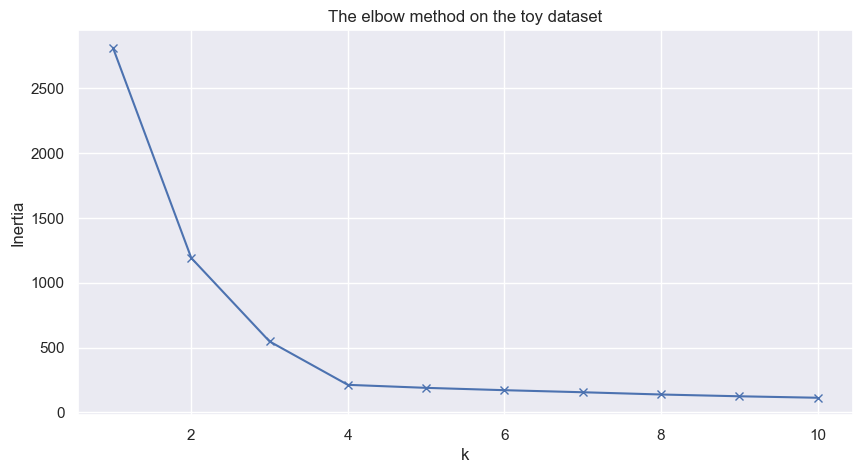

In [ ]:
# toy dataset..where we know the ans is 4
inertias_blobs = []
k_blobs=range(1,11)
for k in k_blobs:
    model=KMeans(n_clusters=k,n_init=10,random_state=0)
    model.fit(X)
    inertias_blobs.append(model.inertia_)
plt.figure(figsize=(10,5))
plt.plot(k_blobs,inertias_blobs,'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('The elbow method on the toy dataset')
plt.show()

Here the elbow is very clear...the inertia drops steeply untill k=4(from about 2800 to about 200) and barely decreases after that.adding a fifth cluster would omly split one of the 4 groups in two which is hardly makes the clusters more compact....so the lbow method suggest k for this dataset is 4

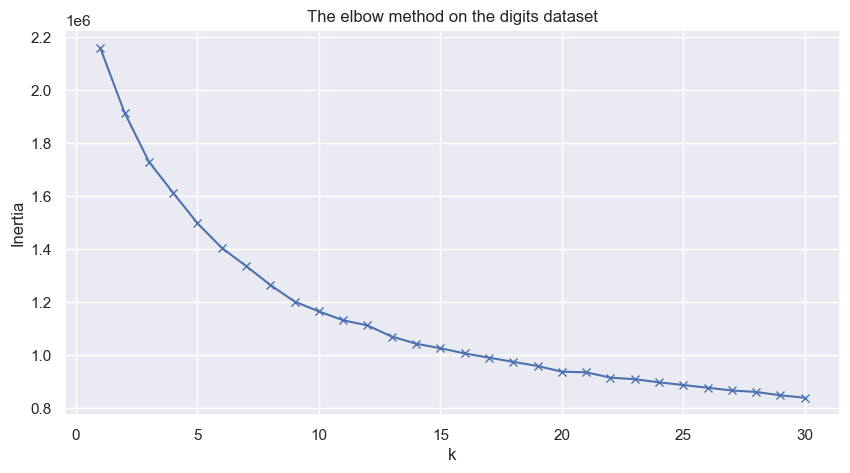

In [18]:
# for digits dataset...k going from 1-30
inertias= []
k_blobs=range(1,31)
for k in k_blobs:
    model=KMeans(n_clusters=k,n_init=10,random_state=0)
    model.fit(digits.data)
    inertias.append(model.inertia_)
plt.figure(figsize=(10,5))
plt.plot(k_blobs,inertias,'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('The elbow method on the digits dataset')
plt.show()

unlike the toy dataset,,,the digits dataset do not show a clear elbow...the inertia decreases quickly at first (from about 2.16 million at k=1 to about 1.17 million at k =10) but it keeps decreasing steadly after that (to about 0.84 million at k=30).The curve bends gradually instead of at one sharp point...so we cannot read an optimal k from this plot. at most we could say that the curve starts flattening somewhere between k=8 and k = 12

- some digits overlap (as qw saw with the 1,8 and 9), so merging or splitting them doesnt cause a sudden jump in inertia
- some digits are written in several different styles(like the 1), so splitting them into extra clusters keeps reducing the inertia

# silhouette score
for everypoint, it compares the average distance to the other points in its own cluster with the average distance to the points in the nearest other cluster.The score ranges from -1 to 1:
- close to 1: The point is much closer to its own cluster than to any other cluster(well-separated clusters)
- close to 0: the point lies on the border between two cluster(overlapping clusters)
- negetive: the point is probably in the wrong cluster
- unlike the inertia the silhouette score doesnt automatically imporve when k increases...so we can simply look for the highest score

Best k: 9 with a silhouette score of 0.189


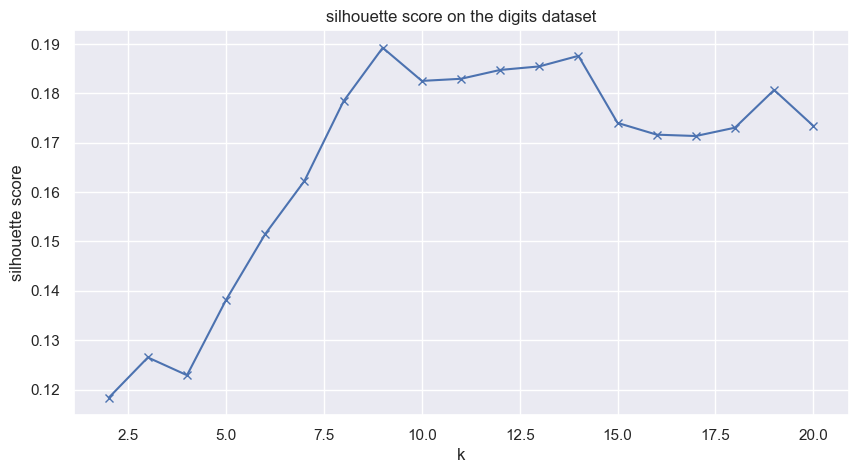

In [21]:
silhouette= []
k_silhouette=range(2,21) #atleast 2 cluster needed for silhouette
for k in k_silhouette:
    model=KMeans(n_clusters=k,n_init=10,random_state=0)
    silhouette.append(silhouette_score(digits.data,model.fit_predict(digits.data)))
print('Best k:', k_silhouette[np.argmax(silhouette)], 'with a silhouette score of %.3f' % max(silhouette))
plt.figure(figsize=(10,5))
plt.plot(k_silhouette,silhouette,'bx-')
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.title('silhouette score on the digits dataset')
plt.show()

The silhouette score increases until about k = 9 (0.189) and then stays almost flat up to k = 14, before dropping. So it points to a range of 9 to 14 clusters, which agrees nicely with our prior knowledge of 10 digits. However, the scores themselves are low (below 0.2): many images lie close to the border between two clusters. This confirms what we saw in the confusion matrix: the digit clusters overlap quite a lot.

# Model validation
- implement a train-test split evaluation of the k-means model. Does the model perform similarly on test data as it does on training data? What might explain any differences or similarities?

- 1 fit kMeans on the training images only
- 2 translate each cluster into a digit using the training labels only
- 3 assign each test image to its nearest cluster center with predict() and translate that cluster into a digit
- 4 compare the training accuracy with the test accuracy

Digit of each cluster (cluster 0 to 9): [7 8 1 4 6 2 5 0 3 1]
Training accuracy: 0.797
Test accuracy:     0.784


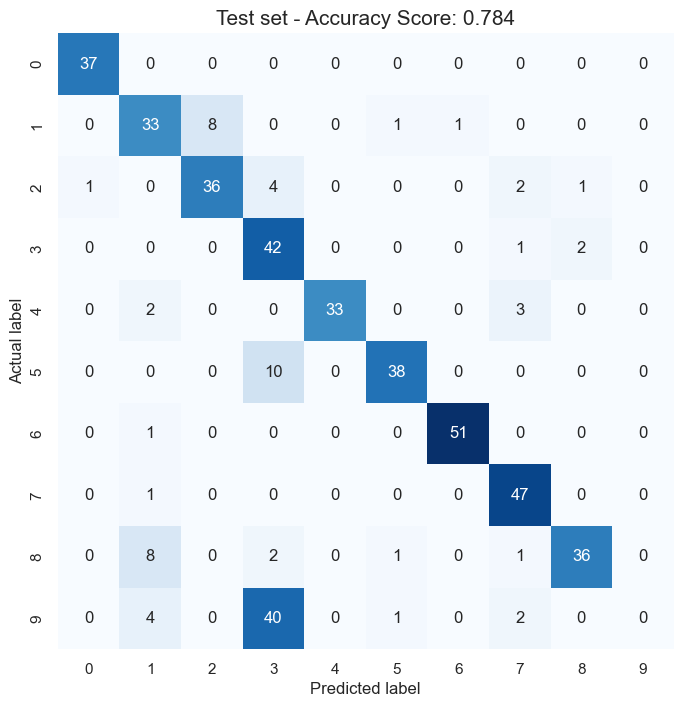

In [22]:
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

# 1. Fit k-means on the training images only (still without using any labels)
kmeans_train = KMeans(n_clusters=10, n_init=10, random_state=0)
train_clusters = kmeans_train.fit_predict(X_train)

# 2. Translate each cluster into a digit, using the training labels only
cluster_to_digit = np.zeros(10, dtype=int)
for i in range(10):
    cluster_to_digit[i] = mode(y_train[train_clusters == i])[0]
print('Digit of each cluster (cluster 0 to 9):', cluster_to_digit)

# 3. Assign each image to its nearest cluster center and look up the digit of that cluster
train_predictions = cluster_to_digit[train_clusters]
test_predictions = cluster_to_digit[kmeans_train.predict(X_test)]

# 4. Compare training and test accuracy
train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)
print('Training accuracy: %.3f' % train_accuracy)
print('Test accuracy:     %.3f' % test_accuracy)

cm = confusion_matrix(y_test, test_predictions)
plt.figure(figsize=(8, 8))
sns.heatmap(cm, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=digits.target_names, yticklabels=digits.target_names)
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Test set - Accuracy Score: %.3f' % test_accuracy, size=15)
plt.show()

The model performs almost the same on both sets: a training accuracy of about 0.797 and a test accuracy of about 0.784. The model generalizes well to images it has never seen. There are two reasons for this:

- k-means is a simple model: it only learns 10 cluster centers, and each center is an average over more than a hundred images. Averages hardly change when a few images are added or removed, so the model can't memorize individual training images. Compare this to k-NN with k = 1 from the previous chapter, which reached a perfect training accuracy by memorizing every training image.
- The labels are only used to name the clusters: the clusters themselves are built from the pixel structure, which is the same in the training and test set.